# Generating multi-frequency CMB + dust data

This guide simulates the data model of `cmb_scattering.simulate_dust` and plots the resulting maps.

Each of the three frequency channels observes the same CMB plus a rescaled copy of one dust field, plus its own noise. Everything is polarization only (E and B):

$$d_\nu = M_\nu B_\nu \,(f + a_\nu\, g) + n_\nu$$

| Symbol | Meaning | Statistics |
|---|---|---|
| $f$ | CMB, the same in every channel (maps are in $\mu K_{\rm CMB}$) | $f \sim N(0, C_f(r))$, with $C_f(r) = C_{\rm lensed\ scalar} + r\, C_{\rm tensor}$ |
| $g$ | dust at the 353 GHz reference frequency | $g \sim N(0, C_g)$, a separate $D_\ell$ power law for EE and BB |
| $a_\nu$ | dust frequency scaling, a modified blackbody relative to 353 GHz | set by $\beta_d$ and $T_d$ |
| $n_\nu$ | white noise, independent between channels | $n_\nu \sim N(0, C_n)$ |
| $M_\nu, B_\nu$ | mask and beam | the identity for now |


## Why a large patch with coarse pixels

The tensor-to-scalar ratio $r$ sets the amplitude of primordial gravitational waves, which are the only primordial source of B-mode polarization. A gravitational wave decays once its wavelength is inside the horizon, so the B-modes it leaves behind sit on scales larger than the horizon at the time the polarization was made:

- **Recombination bump, $\ell \approx 80$.** The horizon at last scattering subtends about $2^\circ$.
- **Reionization bump, $\ell \lesssim 10$.** Photons rescatter after reionization, when the horizon is far larger.

Above $\ell \sim 150$ the tensor signal falls away, while its competitors grow: lensing B-modes behave like white noise of about $5\ \mu K$-arcmin at low $\ell$ and peak near $\ell \sim 1000$, and instrument noise is white too. Almost all the information on $r$ is therefore at $\ell \lesssim 150$.

A flat periodic patch of `nside` pixels of width $\theta_{\rm pix}$ only contains the multipoles

$$\ell_{\min} = \frac{2\pi}{{\tt nside}\ \theta_{\rm pix}}, \qquad \ell_{\rm Nyquist} = \frac{\pi}{\theta_{\rm pix}} .$$

At a fixed `nside` the number of Fourier modes is fixed, and the pixel size decides where they land. Small pixels spend them at high $\ell$, where there is no tensor signal. Coarse pixels move the same modes down to the scales that constrain $r$.

Two costs come with the larger patch. Dust is red ($D_\ell \propto \ell^{\alpha_d}$ with $\alpha_d < 0$), so it is brightest exactly where the tensor signal lives. And the flat-sky approximation degrades as the patch grows, so a patch of tens of degrees is a convenient toy geometry and not a faithful stand-in for a curved sky.


In [5]:
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
from cmb_lensing.util import gen_ell_grid
from cmb_scattering.simulate_dust import (simulate_data, PLANCK_DUST_KNEE_EE,
                                          PLANCK_DUST_BB_TO_EE_AMPLITUDE_RATIO,
                                          DUST_REFERENCE_FREQUENCY_GHZ)

ARCMIN_PER_DEGREE = 60
DEGREES_PER_CIRCLE = 360

def patch_multipoles(nside, theta_pix):
    #(patch width in degrees, lowest multipole, Nyquist multipole) of a flat patch
    width_deg = nside * theta_pix / ARCMIN_PER_DEGREE
    ell_min = DEGREES_PER_CIRCLE / width_deg
    ell_nyquist = DEGREES_PER_CIRCLE * ARCMIN_PER_DEGREE / (2 * theta_pix)
    return width_deg, ell_min, ell_nyquist

nside = 128
#a fine-pixel patch, typical for lensing work, against the coarse patch used below
theta_pix_fine = 2.5
theta_pix = 20.0

for label, pixel in (("fine", theta_pix_fine), ("coarse", theta_pix)):
    width_deg, ell_min, ell_nyquist = patch_multipoles(nside, pixel)
    print(f"{label:>6}: {pixel:4.1f}' pixels, {width_deg:4.1f} deg patch, "
          f"ell from {ell_min:.0f} to {ell_nyquist:.0f}")

  fine:  2.5' pixels,  5.3 deg patch, ell from 68 to 4320
coarse: 20.0' pixels, 42.7 deg patch, ell from 8 to 540


With 2.5' pixels the lowest multipole is already 68, so the recombination bump is covered by a handful of modes and the reionization bump not at all. With 20' pixels the same grid reaches down to $\ell \approx 8$.

## Simulating a data set

`simulate_data` takes the patch geometry, a seed and the model parameters. The values below follow the BICEP/Keck 2018 analysis ([BK18](https://arxiv.org/abs/2110.00483)) for the B-mode dust and [Planck 2018 XI](https://arxiv.org/abs/1801.04945) for the E-mode dust:

- `r = 0.03`, just under the BK18 limit $r < 0.036$ (95%).
- BB dust: $A_d = 4.4\ \mu K^2$ at 353 GHz and $\ell = 80$, $\alpha_d = -0.66$ (BK18 best fit).
- EE dust: BK18 does not fit it, so the amplitude is $A_d / 0.53$ (Planck's BB/EE ratio) and the slope is Planck's $-0.42$.
- $\beta_d = 1.49$ (BK18), with $T_d = 19.6$ K as the default.
- In this toy example we use $3\ \mu K$-arcmin of polarization noise in every channel. In reality, BK18's map depths are 2.8, 2.8 and 8.8 $\mu K$-arcmin at 95, 150 and 220 GHz.


In [13]:
r = 0.03
dust_amplitude_bb = 4.4
dust_knee_bb = -0.66
dust_amplitude_ee = dust_amplitude_bb / PLANCK_DUST_BB_TO_EE_AMPLITUDE_RATIO
dust_knee_ee = PLANCK_DUST_KNEE_EE
frequency_exponent = 1.49
uk_arcmin = 3.0
master_seed = 67

sim = simulate_data(nside, theta_pix, master_seed, r,
                    dust_amplitude_ee, dust_knee_ee, dust_amplitude_bb, dust_knee_bb,
                    frequency_exponent, uk_arcmin = uk_arcmin)

frequencies = np.asarray(jnp.concatenate(sim["frequencies"], jnp.array([DUST_REFERENCE_FREQUENCY_GHZ])))
frequency_scaling = np.asarray(sim["frequency_scaling"])
for frequency, scaling in zip(frequencies, frequency_scaling):
    print(f"{frequency:5.0f} GHz: dust amplitude a = {scaling:.4f} of its 353 GHz value")
print("data E-mode array shape (n_freq, nside, nside//2+1):", sim["data"].polar_matrix_1.shape)

ValueError: Zero-dimensional arrays cannot be concatenated.

In [19]:
jnp.array([DUST_REFERENCE_FREQUENCY_GHZ,])

Array([353.], dtype=float64)

In [18]:
sim["frequencies"]

Array([ 95., 150., 220.], dtype=float64)

In [21]:
jnp.concatenate(sim["frequencies"], jnp.array(DUST_REFERENCE_FREQUENCY_GHZ,))

ValueError: Zero-dimensional arrays cannot be concatenated.

The result is a dict. Its fields are `cmb_lensing` `FlatS2` objects in Fourier space, with E in `polar_matrix_1` and B in `polar_matrix_2`:

- `data` holds all three channels on a leading frequency axis.
- `cmb_field` and `dust_field` are the true $f$ and $g$ (single channel; the dust is at 353 GHz).
- `noise_covariance`, `scalar_covariance`, `tensor_covariance`, `field_covariance` and `dust_covariance` are `DiagonalEB` operators, and `mask` / `beam` are identities.

## What the model puts at each multipole

The covariances are diagonal in Fourier space, and each entry is the spectrum at that mode's multipole divided by the pixel area: the matrices hold $C_\ell / \theta_{\rm pix}^2$ with $\theta_{\rm pix}$ in radians (`pix_width`), the convention of `cmb_lensing`'s `covar_matrix_from_cls`. Reading one row of the grid and multiplying by `pix_width**2` therefore recovers each component's B-mode $C_\ell$, plotted here as $D_\ell = \ell(\ell+1)C_\ell / 2\pi$.


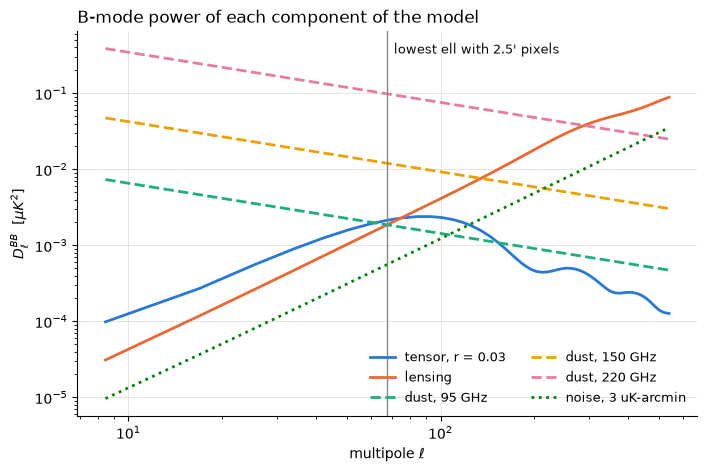

In [3]:
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

ell_grid, pix_width = gen_ell_grid(nside, theta_pix)
ells = np.asarray(ell_grid)[0, 1:]

def bb_dl(operator, channel = None):
    #D_ell of an operator's BB block along the first row of the rfft2 grid, in uK^2
    matrix = np.asarray(operator.matrix_BB)
    matrix = matrix if channel is None else matrix[channel]
    return ells * (ells + 1) * matrix[0, 1:] * pix_width**2 / (2 * np.pi)

fig, ax = plt.subplots(figsize = (8, 5))
ax.loglog(ells, bb_dl(sim["tensor_covariance"]) * r, color = SERIES[0], lw = 2,
          label = f"tensor, r = {r}")
ax.loglog(ells, bb_dl(sim["scalar_covariance"]), color = SERIES[1], lw = 2, label = "lensing")
for channel, (frequency, scaling) in enumerate(zip(frequencies, frequency_scaling)):
    ax.loglog(ells, bb_dl(sim["dust_covariance"]) * scaling**2, color = SERIES[2 + channel],
              lw = 2, ls = "--", label = f"dust, {frequency:.0f} GHz")
ax.loglog(ells, bb_dl(sim["noise_covariance"], channel = 0), color = SERIES[5], lw = 2,
          ls = ":", label = f"noise, {uk_arcmin:g} uK-arcmin")

#the lowest multipole the fine-pixel patch would have reached
_, ell_min_fine, _ = patch_multipoles(nside, theta_pix_fine)
ax.axvline(ell_min_fine, color = MUTED, lw = 1)
ax.text(ell_min_fine * 1.05, 0.97, f"lowest ell with {theta_pix_fine}' pixels", color = INK,
        fontsize = 9, va = "top", transform = ax.get_xaxis_transform())

ax.set_xlabel(r"multipole $\ell$")
ax.set_ylabel(r"$D_\ell^{BB}$  [$\mu K^2$]")
ax.set_title("B-mode power of each component of the model", loc = "left")
ax.grid(color = GRID, lw = 0.6)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon = False, fontsize = 9, ncols = 2, loc = "lower right")
plt.show()

Everything to the left of the grey line is only available because of the coarse pixels. The tensor curve peaks at the recombination bump near $\ell \approx 80$ and drops below the lensing curve beyond $\ell \approx 70$. Dust exceeds the tensor signal at the lowest multipoles even at 95 GHz, and by about two orders of magnitude at 220 GHz, which is why several channels are needed to separate it.

## The simulated maps

A Fourier-space matrix becomes a map through `irfft2`. First the two sky components on their own.


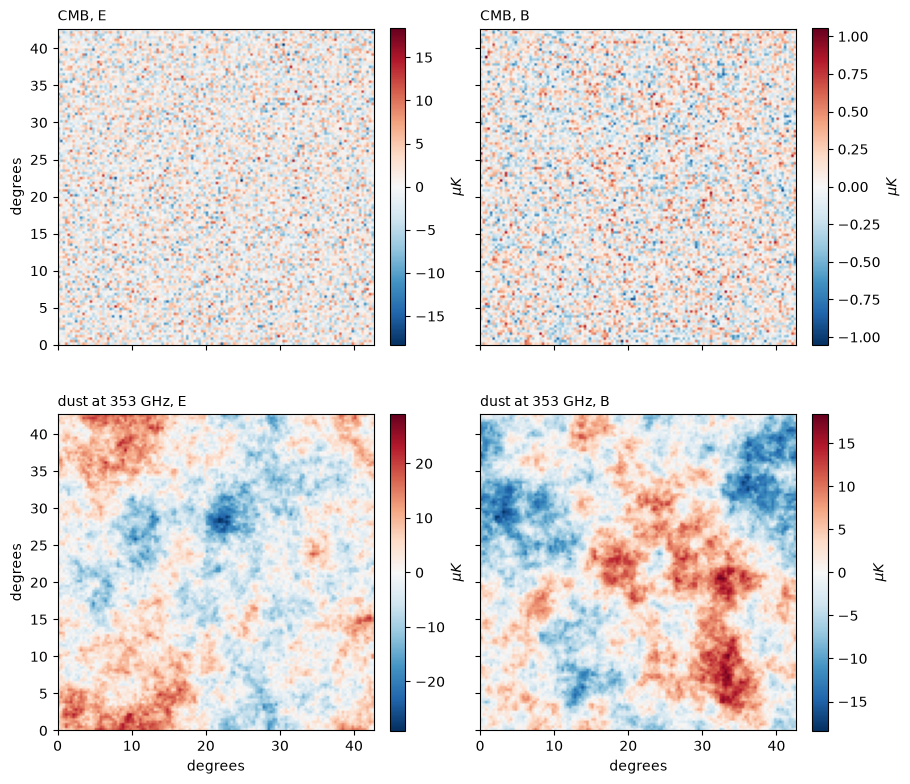

In [4]:
DIVERGING = "RdBu_r"
width_deg, _, _ = patch_multipoles(nside, theta_pix)
extent = (0, width_deg, 0, width_deg)

def to_map(matrix):
    #real-space map (uK) of an rfft2 matrix; works with a leading frequency axis
    return np.fft.irfft2(np.asarray(matrix))

def show_map(ax, values, limit, title):
    #a map on a colour scale symmetric about zero
    image = ax.imshow(values, origin = "lower", extent = extent, cmap = DIVERGING,
                      vmin = -limit, vmax = limit)
    ax.set_title(title, loc = "left", fontsize = 10)
    return image

components = (("CMB", sim["cmb_field"]), ("dust at 353 GHz", sim["dust_field"]))
fig, axes = plt.subplots(2, 2, figsize = (9, 8), sharex = True, sharey = True,
                         constrained_layout = True)
for row, (name, field) in enumerate(components):
    for column, (mode, matrix) in enumerate((("E", field.polar_matrix_1),
                                             ("B", field.polar_matrix_2))):
        values = to_map(matrix)
        image = show_map(axes[row, column], values, np.abs(values).max(), f"{name}, {mode}")
        fig.colorbar(image, ax = axes[row, column], shrink = 0.85, label = r"$\mu K$")
for ax in axes[-1]:
    ax.set_xlabel("degrees")
for ax in axes[:, 0]:
    ax.set_ylabel("degrees")
plt.show()

Each panel has its own colour scale, because the components differ by orders of magnitude: the CMB E-mode is several $\mu K$, the CMB B-mode a few tenths, and the dust at 353 GHz is much brighter than either. The dust maps are dominated by the largest scales, as its red spectrum implies.

Now the data: the three channels a telescope would actually record.


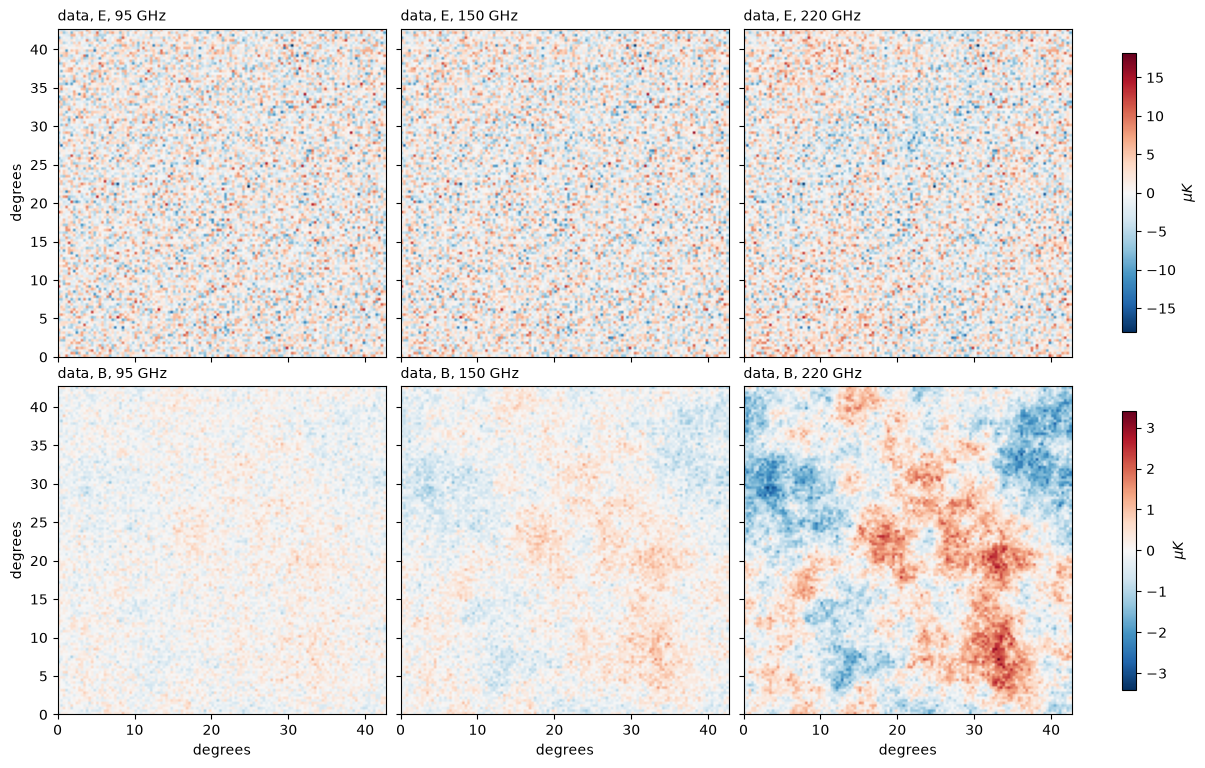

In [5]:
data_maps = {"E": to_map(sim["data"].polar_matrix_1), "B": to_map(sim["data"].polar_matrix_2)}

fig, axes = plt.subplots(2, 3, figsize = (12, 7.5), sharex = True, sharey = True,
                         constrained_layout = True)
for row, (mode, maps) in enumerate(data_maps.items()):
    #one colour scale per row so the channels can be compared directly
    limit = np.abs(maps).max()
    for channel, frequency in enumerate(frequencies):
        image = show_map(axes[row, channel], maps[channel], limit,
                         f"data, {mode}, {frequency:.0f} GHz")
    fig.colorbar(image, ax = axes[row], shrink = 0.85, label = r"$\mu K$")
for ax in axes[-1]:
    ax.set_xlabel("degrees")
for ax in axes[:, 0]:
    ax.set_ylabel("degrees")
plt.show()

Within a row the colour scale is shared. The E-mode maps look almost identical across channels because the CMB E-mode dominates them and the CMB does not change with frequency. The B-mode maps change visibly: the large-scale dust pattern strengthens from 95 to 220 GHz, on top of pixel-scale noise. That frequency dependence is what lets the dust be separated from a primordial B-mode signal.

Change `master_seed` for a different realization, or `nside` and `theta_pix` to trade sky area against resolution.
